In [3]:
import pandas as pd
import numpy as np
import glob
import json
import requests
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from tqdm import tqdm  # Barre de progression pour Jupyter

# Configuration pour l'affichage
pd.set_option('display.max_columns', None)
%matplotlib inline 
print("✅ Environnement prêt.")

✅ Environnement prêt.


In [25]:
import os


# Chemins vers les dossiers
path_normal = '../data/benign/'
path_attack = '../data/attack/'

def load_jsonl_files(directory, label):
    search_pattern = os.path.join(directory, "*.json")
    all_files = glob.glob(search_pattern)
    
    if not all_files:
        print(f"⚠️ Aucun fichier trouvé dans {directory}")
        return pd.DataFrame()

    data_list = []
    
    for filename in all_files:
        with open(filename, 'r', encoding='utf-8') as f:
            for line_number, line in enumerate(f, 1):
                line = line.strip()
                if not line: continue  # Ignore les lignes vides
                
                try:
                    # On décode chaque ligne individuellement
                    item = json.loads(line)
                    item['label'] = label
                    data_list.append(item)
                except json.JSONDecodeError:
                    # Parfois la première ou dernière ligne est mal formée
                    continue 

    print(f"✅ Chargé {len(data_list)} lignes depuis {directory}")
    return pd.DataFrame(data_list)

# 1. Chargement
df_normal = load_jsonl_files(path_normal, 0)
df_attack = load_jsonl_files(path_attack, 1)

# 2. Fusion
if not df_normal.empty or not df_attack.empty:
    df = pd.concat([df_normal, df_attack], ignore_index=True)
    print(f"\n🚀 Dataset finale prête ! Forme : {df.shape}")
else:
    print("❌ Erreur : Aucune donnée n'a pu être chargée.")

✅ Chargé 874923 lignes depuis ../data/benign/
✅ Chargé 290089 lignes depuis ../data/attack/

🚀 Dataset finale prête ! Forme : (1165012, 4)


In [10]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1165012 entries, 0 to 1165011
Data columns (total 4 columns):
 #   Column      Non-Null Count    Dtype 
---  ------      --------------    ----- 
 0   general     1165012 non-null  object
 1   @timestamp  1165012 non-null  object
 2   mqtt        1165012 non-null  object
 3   label       1165012 non-null  int64 
dtypes: int64(1), object(3)
memory usage: 35.6+ MB


In [9]:
df.head()

,general,@timestamp,mqtt,label
0,"{'device_name': 'ard-w-12', 'application': 'Ul...",2025-09-09T23:35:57.782Z,"{'retained': False, 'qos': 0, 'message_value':...",0
1,"{'device_name': 'ard-w-02', 'application': 'So...",2025-09-09T23:35:58.134Z,"{'retained': False, 'qos': 0, 'message_value':...",0
2,"{'device_name': 'ard-w-06', 'application': 'Wa...",2025-09-09T23:35:58.303Z,"{'retained': False, 'qos': 0, 'message_value':...",0
3,"{'device_name': 'ard-w-01', 'application': 'We...",2025-09-09T23:35:58.354Z,"{'retained': False, 'qos': 0, 'message_value':...",0
4,"{'device_name': 'ard-w-01', 'application': 'We...",2025-09-09T23:35:58.361Z,"{'retained': False, 'qos': 0, 'message_value':...",0


Pour que modèle puisse apprendre, nous devons "aplatir" (flatten) ces colonnes pour extraire les vraies variables (device_name, qos, message_value, etc.) dans leurs propres colonnes.

In [11]:
# 1. Extraction des données de la colonne 'general'
df_general = pd.json_normalize(df['general'])

# 2. Extraction des données de la colonne 'mqtt'
df_mqtt = pd.json_normalize(df['mqtt'])

# 3. Récupération du timestamp et du label
df_final = pd.concat([
    df_general, 
    df_mqtt, 
    df['@timestamp'], 
    df['label']
], axis=1)

# Vérifions le résultat
print("Nouvelles colonnes :", df_final.columns)

Nouvelles colonnes : Index(['device_name', 'application', 'ip', 'full_id', 'mac', 'retained', 'qos',
       'message_value', 'topic', 'message_id', 'message_type', 'duplicate',
       '@timestamp', 'label'],
      dtype='object')


In [12]:
# Affiche les 5 premières lignes
display(df_final.head())

,device_name,application,ip,full_id,mac,retained,qos,message_value,topic,message_id,message_type,duplicate,@timestamp,label
0,ard-w-12,Ultrasonic,192.168.1.17,08:B6:1F:82:EE:C4_192.168.1.17_iiot/ultrasonic,08:B6:1F:82:EE:C4,False,0,280.0,iiot/ultrasonic,0,numeric,False,2025-09-09T23:35:57.782Z,0
1,ard-w-02,Soil,192.168.1.12,F0:08:D1:CE:CF:0C_192.168.1.12_iiot/soil,F0:08:D1:CE:CF:0C,False,0,32.0,iiot/soil,0,numeric,False,2025-09-09T23:35:58.134Z,0
2,ard-w-06,Water,192.168.1.11,08:B6:1F:84:66:78_192.168.1.11_iiot/water,08:B6:1F:84:66:78,False,0,1023.0,iiot/water,0,numeric,False,2025-09-09T23:35:58.303Z,0
3,ard-w-01,Weather,192.168.1.10,08:B6:1F:82:12:30_192.168.1.10_iiot/weather/temp,08:B6:1F:82:12:30,False,0,23.2,iiot/weather/temp,0,numeric,False,2025-09-09T23:35:58.354Z,0
4,ard-w-01,Weather,192.168.1.10,08:B6:1F:82:12:30_192.168.1.10_iiot/weather/li...,08:B6:1F:82:12:30,False,0,42.0,iiot/weather/lineartemp,0,numeric,False,2025-09-09T23:35:58.361Z,0


In [47]:
print(df_final['message_type'].head(600)) 

0      numeric
1      numeric
2      numeric
3      numeric
4      numeric
        ...   
595    numeric
596    numeric
597    numeric
598      array
599    numeric
Name: message_type, Length: 600, dtype: object


In [13]:
# Résumé statistique (moyenne, min, max, etc.)
print(df_final.describe())

             qos  message_id         label
count  1165012.0   1165012.0  1.165012e+06
mean         0.0         0.0  2.490009e-01
std          0.0         0.0  4.324345e-01
min          0.0         0.0  0.000000e+00
25%          0.0         0.0  0.000000e+00
50%          0.0         0.0  0.000000e+00
75%          0.0         0.0  0.000000e+00
max          0.0         0.0  1.000000e+00


In [14]:
print("Répartition des Labels (0=Sain, 1=Attaque) :")
print(df_final['label'].value_counts())

print("\nNombre de messages par appareil :")
print(df_final['device_name'].value_counts().head(10))

print("\nTop 5 des Topics MQTT les plus actifs :")
print(df_final['topic'].value_counts().head(5))

Répartition des Labels (0=Sain, 1=Attaque) :
label
0    874923
1    290089
Name: count, dtype: int64

Nombre de messages par appareil :
device_name
ard-w-01    367529
ard-w-15    166330
ard-w-03    114653
ard-w-07    114557
ard-w-10    114525
ard-w-06     57393
ard-w-02     57379
ard-w-08     57372
ard-w-12     56604
ard-w-11     22844
Name: count, dtype: int64

Top 5 des Topics MQTT les plus actifs :
topic
iiot/water          57393
iiot/soil           57379
iiot/steam          57372
iiot/sound/big      57328
iiot/sound/small    57325
Name: count, dtype: int64


In [15]:
print(df_final.dtypes)

device_name      object
application      object
ip               object
full_id          object
mac              object
retained           bool
qos               int64
message_value    object
topic            object
message_id        int64
message_type     object
duplicate          bool
@timestamp       object
label             int64
dtype: object


In [16]:
df_attacks_only = df_final[df_final['label'] == 1]

# Voir les 10 premières attaques
display(df_attacks_only.head(10))

# Voir combien il y en a au total
print(f"Nombre total de messages d'attaque : {len(df_attacks_only)}")

,device_name,application,ip,full_id,mac,retained,qos,message_value,topic,message_id,message_type,duplicate,@timestamp,label
874923,ard-w-01,Weather,192.168.1.10,08:B6:1F:82:12:30_192.168.1.10_iiot/weather/an...,08:B6:1F:82:12:30,False,0,40.81,iiot/weather/analogtemp,0,numeric,False,2025-01-16T14:20:11.418Z,1
874924,ard-w-01,Weather,192.168.1.10,08:B6:1F:82:12:30_192.168.1.10_iiot/weather/bm...,08:B6:1F:82:12:30,False,0,21.5,iiot/weather/bmp180/temp,0,numeric,False,2025-01-16T14:20:11.419Z,1
874925,ard-w-01,Weather,192.168.1.10,08:B6:1F:82:12:30_192.168.1.10_iiot/weather/bm...,08:B6:1F:82:12:30,False,0,79.48,iiot/weather/bmp180/altitude,0,numeric,False,2025-01-16T14:20:11.419Z,1
874926,ard-w-15,Light-Gesture-Proximity,192.168.1.18,8C:AA:B5:8A:A9:B4_192.168.1.18_iiot/light/rgb,8C:AA:B5:8A:A9:B4,False,0,"[159.0, 287.0, 252.0]",iiot/light/rgb,0,array,False,2025-01-16T14:20:11.557Z,1
874927,ard-w-07,Gas,192.168.1.14,08:B6:1F:83:25:98_192.168.1.14_iiot/gas/gas,08:B6:1F:83:25:98,False,0,123.0,iiot/gas/gas,0,numeric,False,2025-01-16T14:20:11.607Z,1
874928,ard-w-07,Gas,192.168.1.14,08:B6:1F:83:25:98_192.168.1.14_iiot/gas/alcohol,08:B6:1F:83:25:98,False,0,37.0,iiot/gas/alcohol,0,numeric,False,2025-01-16T14:20:11.609Z,1
874929,ard-w-03,Sound,192.168.1.15,F0:08:D1:CE:CF:C8_192.168.1.15_iiot/sound/small,F0:08:D1:CE:CF:C8,False,0,210.0,iiot/sound/small,0,numeric,False,2025-01-16T14:20:11.721Z,1
874930,ard-w-08,Steam,192.168.1.13,08:B6:1F:81:D2:CC_192.168.1.13_iiot/steam,08:B6:1F:81:D2:CC,False,0,0.0,iiot/steam,0,numeric,False,2025-01-16T14:20:12.297Z,1
874931,ard-w-01,Weather,192.168.1.10,08:B6:1F:82:12:30_192.168.1.10_iiot/weather/temp,08:B6:1F:82:12:30,False,0,21.9,iiot/weather/temp,0,numeric,False,2025-01-16T14:20:12.530Z,1
874932,ard-w-01,Weather,192.168.1.10,08:B6:1F:82:12:30_192.168.1.10_iiot/weather/bm...,08:B6:1F:82:12:30,False,0,21.5,iiot/weather/bmp180/temp,0,numeric,False,2025-01-16T14:20:12.533Z,1


Nombre total de messages d'attaque : 290089


In [17]:
print("--- IPs les plus utilisées pour les attaques ---")
print(df_attacks_only['ip'].value_counts().head())

print("\n--- Topics les plus ciblés par les attaques ---")
print(df_attacks_only['topic'].value_counts().head())

print("\n--- Types de messages durant l'attaque ---")
print(df_attacks_only['message_type'].value_counts())

--- IPs les plus utilisées pour les attaques ---
ip
192.168.1.10    91736
192.168.1.18    41528
192.168.1.15    28633
192.168.1.19    28611
192.168.1.14    28610
Name: count, dtype: int64

--- Topics les plus ciblés par les attaques ---
topic
iiot/water               14345
iiot/steam               14322
iiot/sound/big           14318
iiot/sound/small         14315
iiot/acceleration/xyz    14308
Name: count, dtype: int64

--- Types de messages durant l'attaque ---
message_type
numeric    244788
array       29565
string      15736
Name: count, dtype: int64


In [20]:
import numpy as np

def clean_value(x):
    # Si c'est une liste, on prend la moyenne des éléments
    if isinstance(x, list):
        return float(np.mean(x)) if len(x) > 0 else 0.0
    # Si c'est déjà un nombre ou une chaîne convertible
    try:
        return float(x)
    except (TypeError, ValueError):
        # Si c'est du texte non numérique (ex: "ON"), on met 0.0
        return 0.0

# Application de la fonction
df_final['message_value'] = df_final['message_value'].apply(clean_value)

# Maintenant, le calcul de la moyenne fonctionnera !
print("Moyenne message_value (Sain) :", df_final[df_final['label'] == 0]['message_value'].mean())
print("Moyenne message_value (Attaque) :", df_final[df_final['label'] == 1]['message_value'].mean())

Moyenne message_value (Sain) : 4744.995374316749
Moyenne message_value (Attaque) : 4707.565473699451


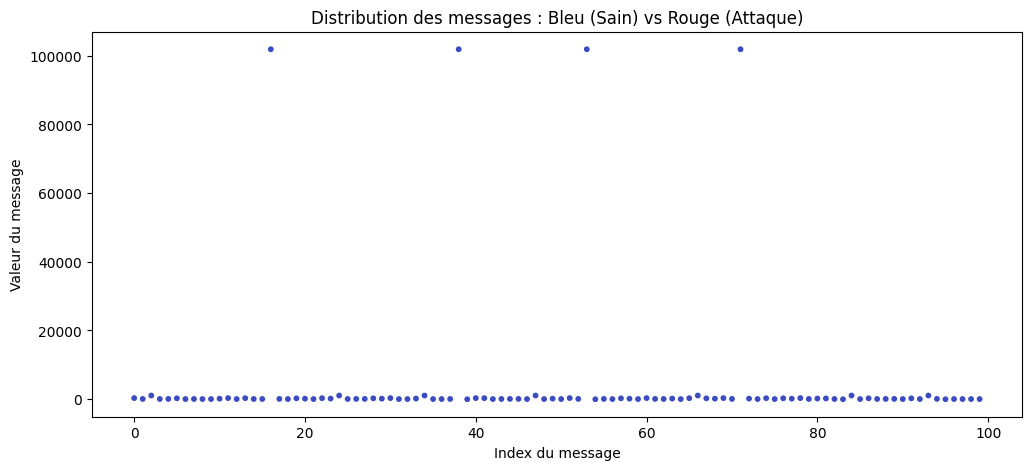

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
# On trace les 1000 premières lignes pour la clarté
plt.scatter(range(100), df_final['message_value'].iloc[:100], c=df_final['label'].iloc[:100], cmap='coolwarm', s=10)
plt.title("Distribution des messages : Bleu (Sain) vs Rouge (Attaque)")
plt.xlabel("Index du message")
plt.ylabel("Valeur du message")
plt.show()

Nettoyage des données

In [27]:
# Calcul du nombre de valeurs manquantes par colonne
missing_values = df_final.isnull().sum()

# Calcul du pourcentage
missing_percent = (df_final.isnull().sum() / len(df)) * 100

# Création d'un tableau récapitulatif
missing_report = pd.DataFrame({
    'Valeurs Manquantes': missing_values,
    'Pourcentage (%)': missing_percent.round(2)
})

print("--- Rapport des valeurs manquantes ---")
print(missing_report[missing_report['Valeurs Manquantes'] > 0])

--- Rapport des valeurs manquantes ---
Empty DataFrame
Columns: [Valeurs Manquantes, Pourcentage (%)]
Index: []


In [28]:
# Compter les doublons exacts
nb_doublons = df_final.duplicated().sum()
print(f"Nombre de lignes en double : {nb_doublons}")

# Suppression si nécessaire
if nb_doublons > 0:
    df_final = df_final.drop_duplicates()
    print("Doublons supprimés pour éviter de biaiser l'IA.")

Nombre de lignes en double : 220
Doublons supprimés pour éviter de biaiser l'IA.


In [29]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# 1. Extraction du temps (Enrichissement)
# Le '@timestamp' est un objet, on le convertit en format datetime pour extraire l'heure
df_final['@timestamp'] = pd.to_datetime(df_final['@timestamp'])
df_final['hour'] = df_final['@timestamp'].dt.hour
df_final['minute'] = df_final['@timestamp'].dt.minute
df_final['second'] = df_final['@timestamp'].dt.second

# 2. Encodage des variables catégorielles (Transformation)
# On transforme les noms (device, topic, ip) en numéros uniques
le = LabelEncoder()

categorical_cols = ['device_name', 'application', 'ip', 'topic', 'message_type']

for col in categorical_cols:
    # On s'assure que tout est en string avant d'encoder
    df_final[f'{col}_enc'] = le.fit_transform(df_final[col].astype(str))

# 3. Traitement de la valeur du message
# Si message_value contient des chiffres, on les force en float. Sinon, 0.
df_final['message_val_num'] = pd.to_numeric(df_final['message_value'], errors='coerce').fillna(0)

# 4. Conversion des booleens en entiers (0 ou 1)
df_final['retained'] = df_final['retained'].astype(int)
df_final['duplicate'] = df_final['duplicate'].astype(int)

In [31]:
# Sélection des caractéristiques finales (Features)
features = [
    'device_name_enc', 'application_enc', 'ip_enc', 'topic_enc', 
    'message_type_enc', 'qos', 'retained', 'duplicate', 
    'message_val_num', 'hour', 'minute', 'second'
]

X = df_final[features]
y = df_final['label']

print("--- Dataset prêt pour l'entraînement ---")
print(f"Nombre de caractéristiques : {X.shape[1]}")
print(X.head(100))

--- Dataset prêt pour l'entraînement ---
Nombre de caractéristiques : 12
    device_name_enc  application_enc  ip_enc  topic_enc  message_type_enc  \
0                11               10       7         20                 1   
1                 1                7       2         16                 1   
2                 5               12       1         22                 1   
3                 0               13       0         29                 1   
4                 0               13       0         28                 1   
..              ...              ...     ...        ...               ...   
95                0               13       0         24                 1   
96               13                3       8          6                 1   
97               13                3       8          8                 0   
98                8                6      12         15                 1   
99                8                6      12         14                 2   

  

In [32]:
# Vérification ultime : doit retourner 0
print(f"Total des valeurs nulles dans X : {X.isnull().sum().sum()}")

Total des valeurs nulles dans X : 0


In [33]:
# Vérifier les types de colonnes
print("Types de données dans le dataset final :")
print(X.dtypes.unique()) 
# Si vous voyez 'object', le nettoyage n'est PAS fini.

Types de données dans le dataset final :
[dtype('int64') dtype('float64') dtype('int32')]


In [34]:
# Vérifier s'il reste des lignes identiques
print(f"Nombre de doublons restants : {X.duplicated().sum()}")

Nombre de doublons restants : 29446


In [35]:
# Vérifier l'équilibre entre attaques (1) et bénins (0)
print("Répartition des labels :")
print(y.value_counts(normalize=True) * 100)

Répartition des labels :
label
0    75.112123
1    24.887877
Name: proportion, dtype: float64


In [36]:
# On regroupe X et y pour s'assurer de supprimer les doublons sur l'ensemble
df_temp = pd.concat([X, y], axis=1)

# Suppression des doublons
df_temp = df_temp.drop_duplicates()

# On sépare à nouveau
X = df_temp.drop(columns=['label'])
y = df_temp['label']

print(f"Nettoyage final terminé. Nouveau nombre de lignes : {len(X)}")
print(f"Doublons restants : {X.duplicated().sum()}")

Nettoyage final terminé. Nouveau nombre de lignes : 1155008
Doublons restants : 19662


In [37]:
# Vérification des lignes qui ont les mêmes features mais des labels différents
conflicts = X[X.duplicated(keep=False)].index
print(f"Nombre de lignes suspectes : {len(conflicts)}")

Nombre de lignes suspectes : 39324


39 324 lignes suspectes, c'est énorme ! Cela signifie que vous avez près de 40 000 messages qui ont exactement les mêmes caractéristiques (même heure, même IP, même topic, même valeur de capteur) mais qui sont étiquetés différemment (parfois "Attaque", parfois "Bénin").

En cybersécurité, on appelle cela du bruit ou des étiquettes contradictoires. Si vous laissez ces données ainsi, votre modèle d'IA va "hésiter" et ses performances seront médiocres.

Pourquoi est-ce un problème ?
Imaginez que vous apprenez à un enfant qu'une pomme rouge est un fruit, puis le lendemain vous lui dites qu'une pomme rouge identique est un caillou. Il sera incapable de décider face à la prochaine pomme.

La Solution : Nettoyage par Consensus
Pour atteindre le 100% de propreté, nous allons appliquer une règle simple : si une ligne est ambiguë, nous la supprimons pour ne garder que les exemples où le comportement est clair.

In [38]:
# 1. Identifier les lignes où les features sont identiques
# On regroupe par toutes les colonnes de X et on regarde le nombre de labels uniques
df_check = pd.concat([X, y], axis=1)
conflicts = df_check.groupby(features)['label'].nunique()

# 2. On ne garde que les combinaisons de features qui n'ont qu'UN SEUL label possible
valid_features = conflicts[conflicts == 1].index

# 3. Filtrage du dataset original
# On transforme les index valides en DataFrame pour faire une jointure (merge)
df_clean_final = pd.merge(df_check, valid_features.to_frame(index=False), on=features)

# 4. Mise à jour de X et y
X = df_clean_final[features]
y = df_clean_final['label']

print(f"Nettoyage chirurgical terminé.")
print(f"Lignes restantes : {len(X)}")
print(f"Doublons restants dans X : {X.duplicated().sum()}")

Nettoyage chirurgical terminé.
Lignes restantes : 1115684
Doublons restants dans X : 0


In [40]:
print(f"Doublons restants dans Y : {y.duplicated().sum()}")

Doublons restants dans Y : 1115682


In [41]:
# Est-ce que chaque ligne de données est unique ?
print(f"Est-ce que X est propre ? {X.duplicated().sum() == 0}")

# Est-ce que Y contient bien nos deux classes ?
print(f"Classes détectées dans Y : {y.unique()}")

Est-ce que X est propre ? True
Classes détectées dans Y : [0 1]


In [42]:
# Sauvegarder X (features) et y (labels) ensemble pour garder la cohérence
df_clean_final = pd.concat([X, y], axis=1)

# Exportation en CSV
df_clean_final.to_csv('iiot_dataset_clean.csv', index=False)

print("Fichier sauvegardé localement sous le nom 'iiot_dataset_clean.csv'")

Fichier sauvegardé localement sous le nom 'iiot_dataset_clean.csv'
